# 1D Stiff Relaxation: The Explicit Scheme and Its Instability

Toy model (P1 / telegraph analogue of M1 neutrino transport and resistive MHD):

$$\partial_t E + \partial_x F = 0, \qquad \partial_t F + \frac{1}{3}\,\partial_x E = -\kappa F$$

where $E$ is the energy density, $F$ is the energy flux, and $\kappa$ is the opacity / relaxation rate:
- **Small $\kappa$ ($\kappa \to 0$, optically thin):** Waves propagate freely at characteristic speed $c = 1/\sqrt{3}$ (*free streaming*).
- **Large $\kappa$ ($\kappa \gg 1$, optically thick / stiff regime):** The flux quickly relaxes to Fick's law $F \approx -\frac{1}{3\kappa}\partial_x E$, reducing the system to a parabolic diffusion equation: $\partial_t E = D\,\partial_x^2 E$ with $D = 1/(3\kappa)$.

**Goal of this notebook:** Implement the simplest explicit scheme (forward Euler in time, Rusanov flux in space) and observe where and why it breaks down as $\kappa$ increases.

In [1]:
### IMPORT LIBRARIES ###

import numpy as np
import matplotlib.pyplot as plt

# Characteristic speed of the hyperbolic part
c = 1.0 / np.sqrt(3.0)

## 1. The Explicit Numerical Scheme

We discretize the periodic domain $x \in [0, 1]$ using finite volumes with a Rusanov (local Lax-Friedrichs) numerical flux at cell interfaces $i+1/2$:

$$\hat{f}^E_{i+1/2} = \frac{1}{2}(F_i + F_{i+1}) - \frac{c}{2}(E_{i+1} - E_i)$$
$$\hat{f}^F_{i+1/2} = \frac{1}{2}\left(\frac{E_i}{3} + \frac{E_{i+1}}{3}\right) - \frac{c}{2}(F_{i+1} - F_i)$$

The timestep is dictated strictly by the hyperbolic CFL condition, $\Delta t = \text{CFL}\,\Delta x / c$. Nothing in $\Delta t$ accounts for the stiff relaxation timescale $\tau_{\rm rel} = 1/\kappa$, which is the root cause of the instability.

In [2]:
### DEFINE FUNCTION TO SOLVE THE 1D TELEGRAPH/P1 SYSTEM ###

def run_explicit(kappa, N=200, cfl=0.9, tend=0.5, blow=1e8):
    """
    Solve the 1D telegraph/P1 system using forward Euler and Rusanov fluxes.
    Stops early if the solution blows up above `blow`.
    """
    dx = 1.0 / N
    x = (np.arange(N) + 0.5) * dx
    
    # Initial condition: Gaussian energy pulse at rest (F = 0)
    E = np.exp(-(x - 0.5)**2 / (2.0 * 0.05**2))
    F = np.zeros(N)
    
    dt = cfl * dx / c
    t = 0.0
    ts = [0.0]
    Fmax = [0.0]
    
    while t < tend:
        Ep, Fp = np.roll(E, -1), np.roll(F, -1)  # right neighbour (i+1)
        
        # Rusanov fluxes at interface i+1/2
        fE = 0.5 * (F + Fp) - 0.5 * c * (Ep - E)
        fF = 0.5 * (E / 3.0 + Ep / 3.0) - 0.5 * c * (Fp - F)
        
        # Spatial flux divergence + explicit stiff source term
        dE = -(fE - np.roll(fE, 1)) / dx
        dF = -(fF - np.roll(fF, 1)) / dx - kappa * F
        
        # Forward Euler update
        E = E + dt * dE
        F = F + dt * dF
        t += dt
        
        ts.append(t)
        Fmax.append(np.max(np.abs(F)))
        
        if not np.isfinite(Fmax[-1]) or Fmax[-1] > blow:
            break
            
    return x, E, F, np.array(ts), np.array(Fmax), dt

## 2. From Wave Propagation to Diffusion — and Blow-Up

Let us test four values of $\kappa$:
1. $\kappa = 0$: Pure wave propagation (two symmetric pulses moving at $\pm c$).
2. $\kappa = 10$: Damped waves with a diffusive wake.
3. $\kappa = 100$: Diffusive regime (still stable, $\kappa \Delta t \approx 0.78$).
4. $\kappa = 300$: Catastrophic numerical instability ($\kappa \Delta t > 2$).

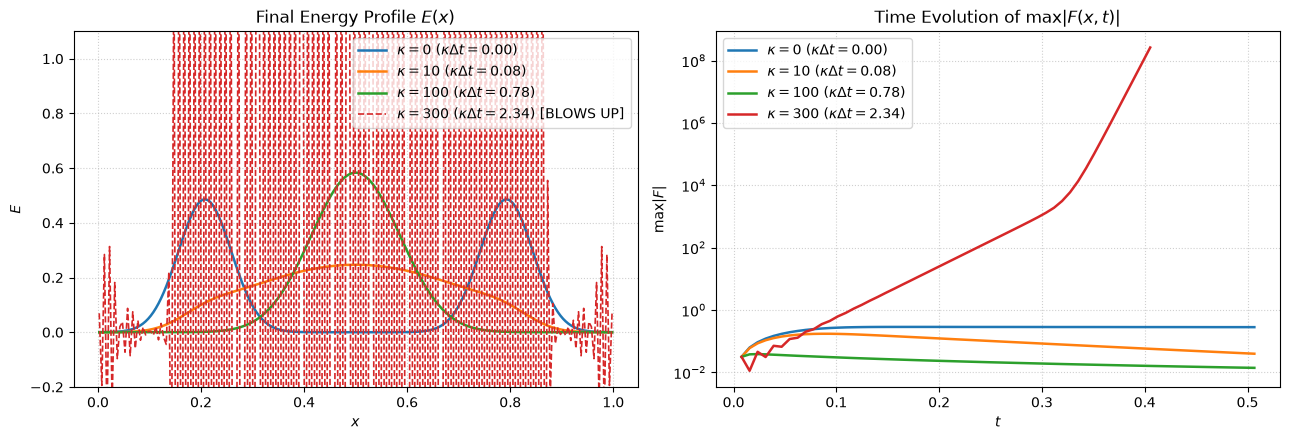

In [3]:
### RUN SIMULATION FOR DIFFERENT KAPPA VALUES AND PLOT RESULTS ###

kappas = [0, 10, 100, 300]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for k in kappas:
    x, E, F, ts, Fmax, dt = run_explicit(k)
    label = rf"$\kappa={k}$ ($\kappa\Delta t={k*dt:.2f}$)"
    
    if Fmax[-1] < 1e4:
        axes[0].plot(x, E, lw=1.8, label=label)
    else:
        axes[0].plot(x, np.clip(E, -2, 2), "--", lw=1.2, label=label + " [BLOWS UP]")
        
    axes[1].semilogy(ts[1:], Fmax[1:], lw=1.8, label=label)

axes[0].set_title(r"Final Energy Profile $E(x)$")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("$E$")
axes[0].set_ylim(-0.2, 1.1)
axes[0].grid(True, ls=":", alpha=0.6)
axes[0].legend()

axes[1].set_title(r"Time Evolution of $\max |F(x,t)|$")
axes[1].set_xlabel("$t$")
axes[1].set_ylabel(r"$\max |F|$")
axes[1].grid(True, ls=":", alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Why Does It Blow Up? The Stability Limit $\kappa \Delta t \le 2$

Ignoring spatial gradients for a moment, the flux relaxation equation reduces to the stiff ODE:

$$\partial_t F = -\kappa F$$

Applying forward Euler yields:

$$F^{n+1} = F^n - \kappa \Delta t F^n = (1 - \kappa \Delta t) F^n$$

For this update not to amplify oscillations exponentially at every step, the amplification factor must satisfy:

$$|1 - \kappa \Delta t| \le 1 \iff \kappa \Delta t \le 2$$

Furthermore, because the spatial Rusanov operator adds numerical dissipation of order $\sim c\,\Delta x / 2$, the actual stability boundary for the full PDE system (specifically at the grid Nyquist mode $k = \pi / \Delta x$) is even tighter: $\kappa \Delta t \lesssim 2 - \text{CFL}$. Let us verify this by scanning across $\kappa$:

dt = 0.007794
Pure ODE stability limit (kappa*dt = 2):       kappa_crit = 256.6
Nyquist PDE stability limit (kappa*dt = 1.1):  kappa_crit = 141.1


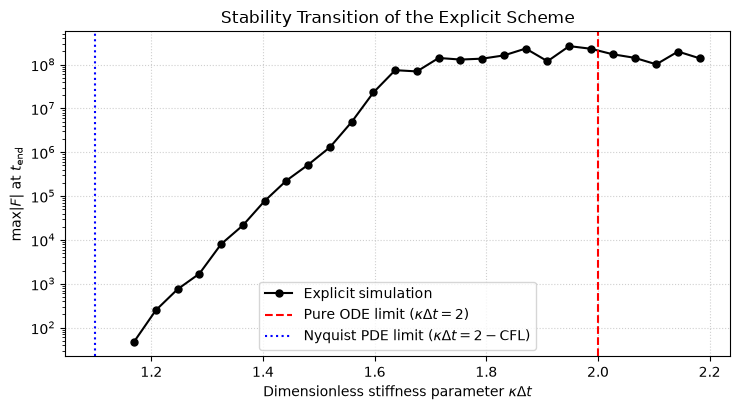

In [4]:
### STABILITY ANALYSIS OF THE EXPLICIT SCHEME ###

_, _, _, _, _, dt = run_explicit(0)
kappa_scan = np.linspace(150, 280, 27)
final_Fmax = []

for k in kappa_scan:
    _, _, _, _, Fmax, _ = run_explicit(k)
    final_Fmax.append(Fmax[-1])

kappa_crit_ode = 2.0 / dt
kappa_crit_pde = (2.0 - 0.9) / dt

print(f"dt = {dt:.6f}")
print(f"Pure ODE stability limit (kappa*dt = 2):       kappa_crit = {kappa_crit_ode:.1f}")
print(f"Nyquist PDE stability limit (kappa*dt = 1.1):  kappa_crit = {kappa_crit_pde:.1f}")

plt.figure(figsize=(7.5, 4.2))
plt.semilogy(kappa_scan * dt, final_Fmax, "ko-", markersize=5, label="Explicit simulation")
plt.axvline(2.0, color="r", ls="--", label=r"Pure ODE limit ($\kappa\Delta t = 2$)")
plt.axvline(2.0 - 0.9, color="b", ls=":", label=r"Nyquist PDE limit ($\kappa\Delta t = 2 - \mathrm{CFL}$)")
plt.xlabel(r"Dimensionless stiffness parameter $\kappa \Delta t$")
plt.ylabel(r"$\max |F|$ at $t_{\rm end}$")
plt.title("Stability Transition of the Explicit Scheme")
plt.grid(True, ls=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()